# Predictive Maintenance ML System

## 01. Data Understanding

### Objective
Understand the structure, contents, data types, target variables,
and initial quality of the predictive maintenance dataset.

In [1]:
import pandas as pd
import seaborn as sns

machine_data = pd.read_csv(r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Predictive-Maintenance-ML\data\raw\predictive_maintenance.csv")
machine_data

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure


In [2]:
machine_data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [3]:
machine_data.shape

(10000, 10)

In [4]:
machine_data.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Target', 'Failure Type'],
      dtype='object')

In [5]:
machine_data.info

<bound method DataFrame.info of         UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0         1     M14860    M                298.1                    308.6   
1         2     L47181    L                298.2                    308.7   
2         3     L47182    L                298.1                    308.5   
3         4     L47183    L                298.2                    308.6   
4         5     L47184    L                298.2                    308.7   
...     ...        ...  ...                  ...                      ...   
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]  

In [6]:
machine_data.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Target                       int64
Failure Type                object
dtype: object

## 02. Missing Values


In [7]:
machine_data.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

## 03. Check duplicate rows

In [8]:
machine_data.duplicated().sum()

np.int64(0)

## 04. Let's understand the categorical columns

In [9]:
machine_data['Type'].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [10]:
machine_data['Failure Type'].value_counts()

Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64

## 05. let's inspect the numerical features

### Numerical Statistical summary

In [11]:
machine_data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


## 06. Visualisation

### 6.1 Distribution analysis - Histogram

In [12]:
import matplotlib.pyplot as plt

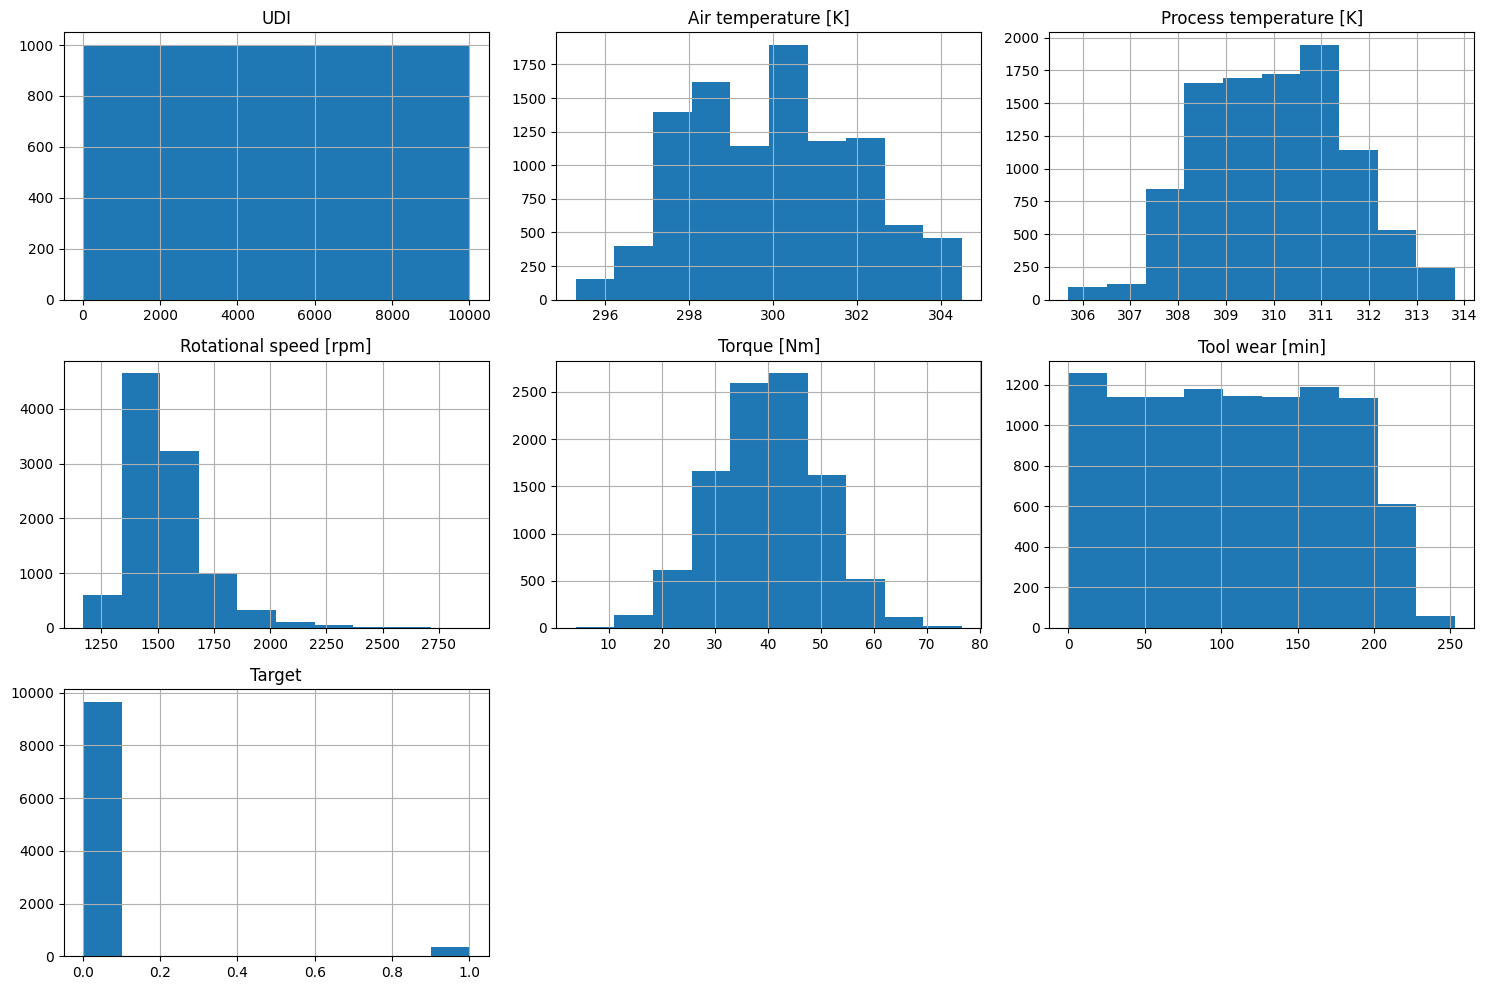

In [13]:
machine_data.hist(figsize=(15,10))
plt.tight_layout()
plt.show()

### 6.2 Boxplots - outlier analysis

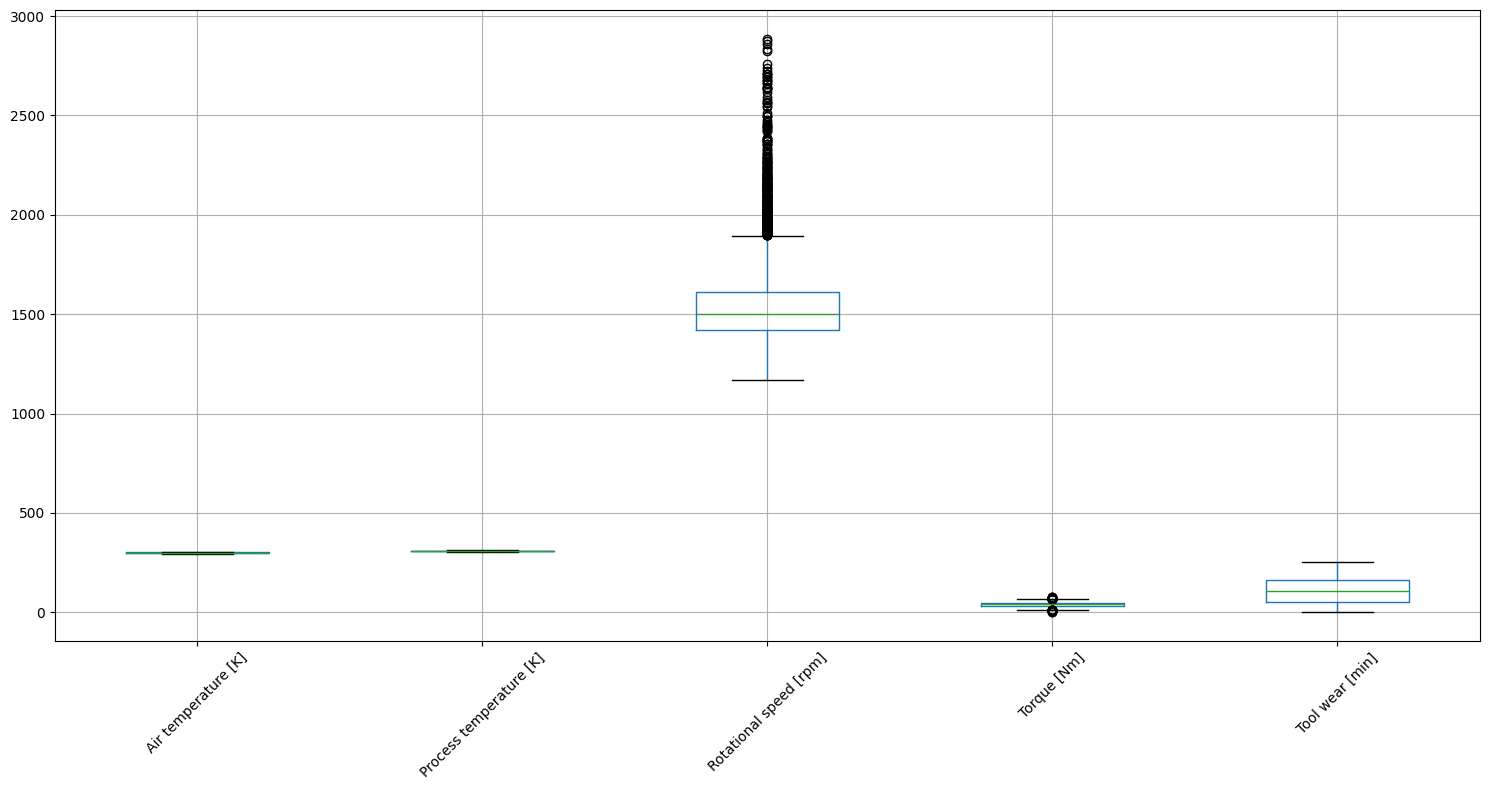

In [14]:
plt.figure(figsize=(15, 8))

machine_data.boxplot(
    column=[
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Torque [Nm]',
        'Tool wear [min]'
    ]
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
machine_data.groupby('Target')[[
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Torque [Nm]',
        'Tool wear [min]'
    ]].mean()
    

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Target,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


## 07. Visualize Features Against Target

In [16]:
features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]


<Figure size 700x500 with 0 Axes>

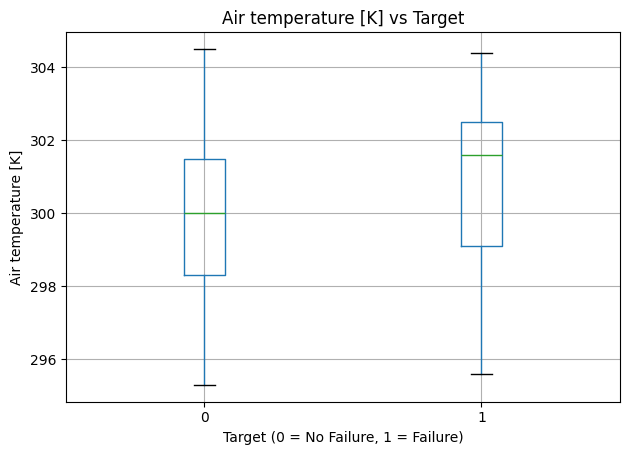

<Figure size 700x500 with 0 Axes>

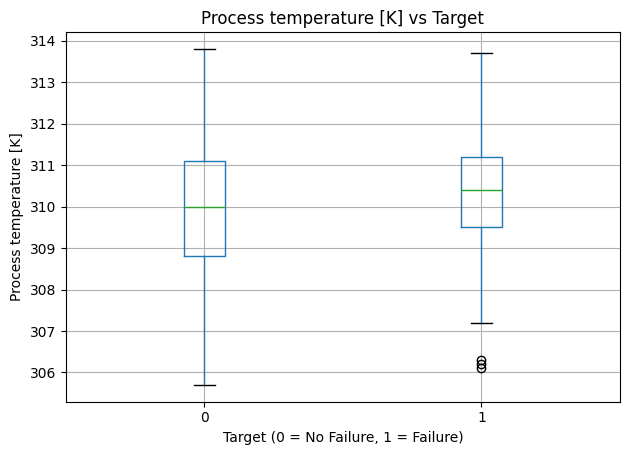

<Figure size 700x500 with 0 Axes>

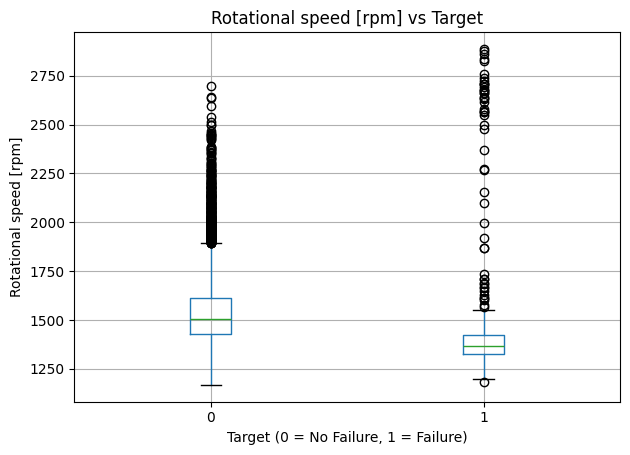

<Figure size 700x500 with 0 Axes>

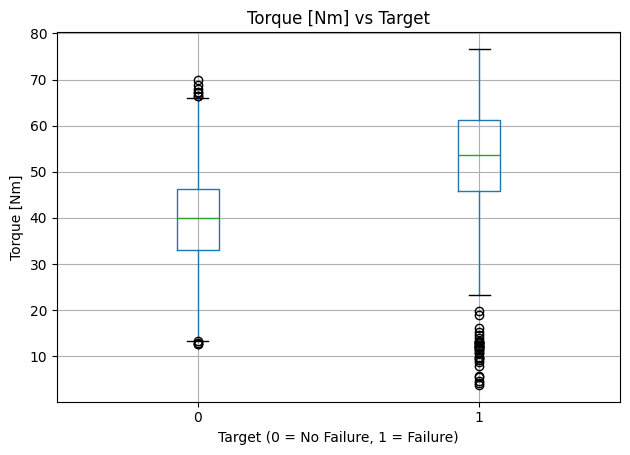

<Figure size 700x500 with 0 Axes>

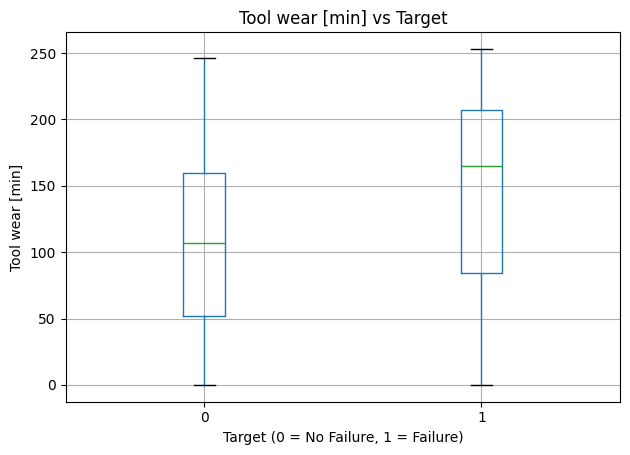

In [17]:
for feature in features:
    plt.figure(figsize=(7,5))

    machine_data.boxplot(
        column=feature,
        by='Target'
    )

    plt.title(f'{feature} vs Target')
    plt.suptitle('')
    plt.xlabel('Target (0 = No Failure, 1 = Failure)')
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()
    

## Correlation Analysis
##### How strongly is each numerical feature linearly related to the target and to other numerical features?

Correlation values range from -1 to +1:

* +1 → strong positive relationship
* -1 → strong negative relationship
* 0 → little/no linear relationship

### 1. Create correlation matrix

In [18]:
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Target'
]

correlation = machine_data[numerical_features].corr()

correlation

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Target,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


### 2. Visualize it with a heatmap

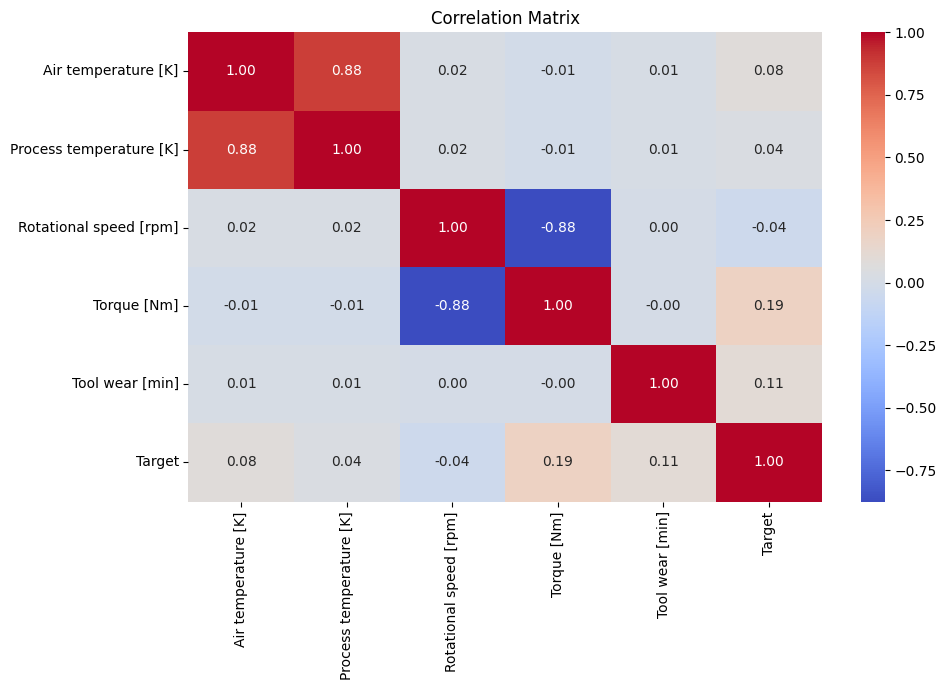

In [19]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

#### Step 3 — Check feature-to-feature correlation

In [20]:
feature_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

feature_corr = machine_data[feature_cols].corr()

feature_corr

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000


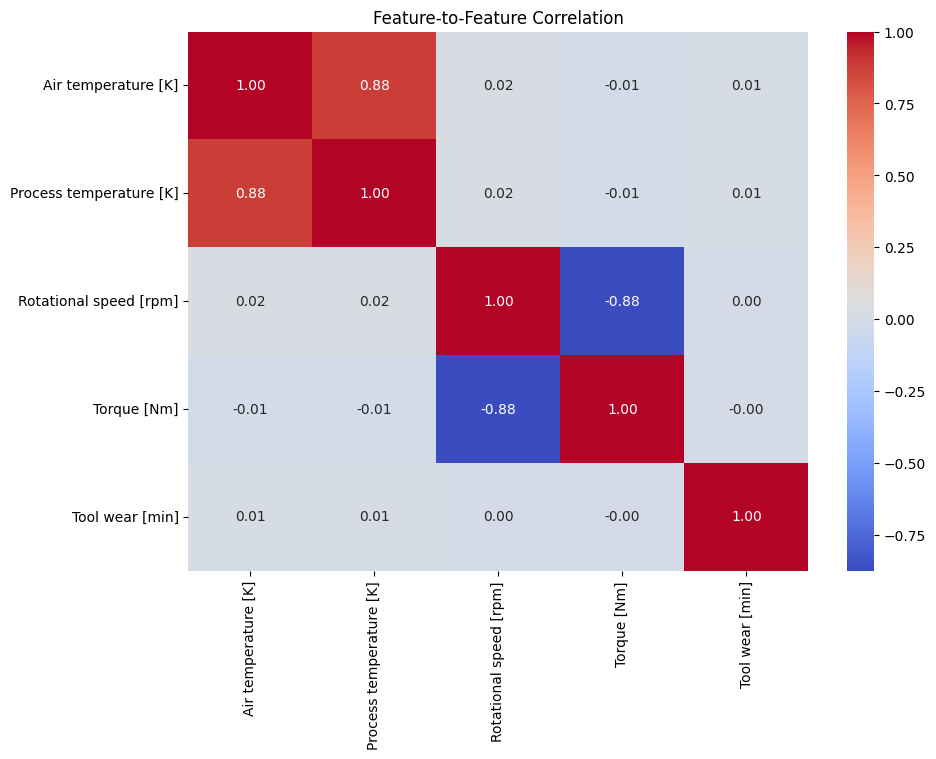

In [21]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature-to-Feature Correlation')
plt.show()

### 13. Train-Test split

#### 13.1 What is Train-Test split
Train-test split means dividing our dataset into two parts:

* Training set → used by the ML model to learn patterns.
* Testing set → used to evaluate how well the trained model performs on unseen data.

For example, with 10,000 records:

                Dataset
             10,000 records
                   │
          ┌────────┴────────┐
          ↓                 ↓
     Training Set       Testing Set
      80% = 8,000       20% = 2,000
          │                 │
      Learn patterns     Evaluate model

The model must not learn from the test data.

#### 13.2 Why do we need it?
Imagine you are preparing for an exam.

If you practice using a set of questions and then evaluate yourself using the same questions, you may get a very high score.

But that doesn't tell us whether you actually understand the subject.

ML is similar.

Training data
     ↓
Model learns
     ↓
Test data
     ↓
Model predicts
     ↓
Evaluate performance

The test set represents unseen data.

#### 13.3 Why should we split before preprocessing?

This is very important.

Suppose you calculate the mean and standard deviation of the entire dataset before splitting.

Then information from the test set has indirectly entered the training process.

This is called data leakage.

##### Correct approach:

Raw Dataset
     ↓
Train-Test Split
     ↓
Training Data ──→ Fit preprocessing
     ↓
Test Data ──────→ Apply preprocessing

For example, later when we use StandardScaler:

* scaler.fit(X_train)
* X_train_scaled = scaler.transform(X_train)
* X_test_scaled = scaler.transform(X_test)

We fit the scaler only on training data.

#### 13.4 Why stratify=y is important in YOUR project

Your target is highly imbalanced:

* Target 0 → 96.52%
* Target 1 → 3.48%

If we randomly split without considering the target distribution, the proportion of failures could vary between training and testing sets.

We therefore use:

* stratify=y

This tries to maintain approximately the same proportion of:

* Target 0
* Target 1

in both datasets.

For your project, this is especially important because failure cases are rare.


In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X = machine_data[
    [
        'Type',
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Torque [Nm]',
        'Tool wear [min]'
    ]
]

y = machine_data['Target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

In [24]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 6)
X_test shape: (2000, 6)
y_train shape: (8000,)
y_test shape: (2000,)


In [25]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
Target
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Target
0    1932
1      68
Name: count, dtype: int64


#### 14. Data Preprocessing

We currently have 6 input features:

| Feature                   | Type        | Preprocessing    |
| ------------------------- | ----------- | ---------------- |
| `Type`                    | Categorical | One-Hot Encoding |
| `Air temperature [K]`     | Numerical   | Standard Scaling |
| `Process temperature [K]` | Numerical   | Standard Scaling |
| `Rotational speed [rpm]`  | Numerical   | Standard Scaling |
| `Torque [Nm]`             | Numerical   | Standard Scaling |
| `Tool wear [min]`         | Numerical   | Standard Scaling |

##### 14.1 Why do we need preprocessing?

Machine learning algorithms cannot always work directly with raw data.

Our dataset contains:

Categorical data
Type

L
M
H

A model cannot directly perform mathematical operations on "L", "M" and "H".

So we need to convert them into numerical representation.

Numerical data

Our numerical features have very different scales:

* Air temperature       ≈ 295–305
* Process temperature   ≈ 305–314
* Rotational speed      ≈ 1168–2886
* Torque                ≈ 3.8–76.6
* Tool wear             ≈ 0–253

Some algorithms are sensitive to these scale differences.

So we standardize the numerical features.

##### 14.2 Encoding Type

We'll use One-Hot Encoding.

For example:

Type
----
L
M
H

becomes something like:

Type_H  Type_L  Type_M
   0       1       0
   0       0       1
   1       0       0

This prevents us from incorrectly implying:

H > M > L

as if the categories were numerical quantities.

##### 14.3 Scaling numerical features

We'll use:

StandardScaler

The formula is:

z=x−μ/σ

where:

x = original value
μ = mean calculated from training data
σ = standard deviation calculated from training data
z = standardized value

After scaling, the numerical features will generally have:

* Mean ≈ 0
* Standard deviation ≈ 1
* Very important

We calculate the mean and standard deviation only using X_train.

We don't allow information from X_test to influence preprocessing.


In [26]:
### 14.4 Identify numerical and categorical columns
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

categorical_features = [
    'Type'
]

In [27]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [28]:
### 14.5 Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [29]:
### 14.6 Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [30]:
preprocessor.fit_transform(X_train)

array([[ 0.99891359,  0.60428162, -0.46060741, ...,  0.        ,
         0.        ,  1.        ],
       [-1.50519408, -1.15325984, -0.77557391, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.49809206,  1.07746586, -1.00765448, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.14751698,  1.00986812, -0.41640159, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.84866713,  0.80707487, -0.12353801, ...,  0.        ,
         1.        ,  0.        ],
       [-0.65379747, -0.20689136, -0.42745305, ...,  0.        ,
         1.        ,  0.        ]], shape=(8000, 8))

In [31]:
preprocessor.transform(X_test)

array([[ 0.24768129, -0.13929361, -1.07396322, ...,  0.        ,
         1.        ,  0.        ],
       [ 1.85031019,  1.61824785, -0.14564092, ...,  0.        ,
         1.        ,  0.        ],
       [ 1.24932436,  0.94227037,  0.10854256, ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [-0.95429039, -1.42365083, -0.51586469, ...,  0.        ,
         0.        ,  1.        ],
       [ 1.1992422 ,  1.28025911, -0.64848216, ...,  0.        ,
         0.        ,  1.        ],
       [-1.0544547 , -0.6800756 ,  2.37961675, ...,  0.        ,
         0.        ,  1.        ]], shape=(2000, 8))

In [32]:
#### 14.7 Check the result 
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (8000, 6)
Processed training shape: (8000, 8)
Original testing shape: (2000, 6)
Processed testing shape: (2000, 8)


In [33]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


### 15. Handling Class Imbalance

#### 15.1 What is class imbalance?

A classification dataset is imbalanced when one class contains many more observations than another.

Your target distribution is:

Target = 0 → 9652 → 96.52%
Target = 1 →  348 →  3.48%

So:

No Failure  ████████████████████████████████████████████████ 96.52%
Failure      ██                                               3.48%

The failure class is the minority class.

#### 15.2 Why is this a problem?

Imagine we create a terrible model that predicts:

Every machine → No Failure

It would correctly classify all 9,652 non-failure records.

Therefore:

Accuracy=9652/10000=96.52%

It looks like an excellent accuracy.

But:

* Actual failures = 348
* Predicted failures = 0

So the model detects zero failures.

For predictive maintenance, this is clearly not useful because the important business event is detecting machines that may fail.

Key lesson:

High accuracy does not necessarily mean a good model when the target classes are highly imbalanced.

### 15.3 What metrics should we care about?

For our project, we'll later evaluate:

Precision

Of the machines predicted as failures, how many actually failed?

Precision=TP/FP+TP​

Recall

Of all the machines that actually failed, how many did the model detect?

Recall=TP/FN+TP​

For predictive maintenance, recall is particularly important to examine because a false negative means:

Actual failure → Model predicted no failure.

That could mean a machine requiring attention is missed.

However, we shouldn't maximize recall blindly because excessive false alarms can also create unnecessary maintenance.

F1-score

F1 combines precision and recall:

F1=2 Precision×Recall/Precision+Recall​

ROC-AUC

Measures how well the model separates the two classes across different classification thresholds.

We'll discuss this properly when we evaluate the model.

#### 15.4 How can we handle class imbalance?

There are several approaches.

Method 1 — Class weights

Tell the model:

Give more importance to the minority failure class.

For example, Logistic Regression supports:

class_weight='balanced'

This is a very useful starting approach for your project.

Method 2 — Oversampling

Increase the number of minority-class observations.

Examples:

Random Oversampling
SMOTE
Method 3 — Undersampling

Reduce the number of majority-class observations.

For example:

9652 non-failure
↓
reduce majority class

But we potentially throw away useful information.

#### 15.5 What should we use for this project?

For the first baseline model, I'd recommend starting with:

class_weight='balanced'

rather than immediately applying SMOTE.

Why?

It's simple, doesn't create synthetic observations, and gives us a clean baseline for comparison.

Later, we can experiment with other imbalance-handling approaches if needed.

#### 15.6 Important: Don't modify the test set

This is critical.

We have:

Original data
      ↓
Train-test split
      ↓
Training data             Testing data
      ↓                         ↓
Handle imbalance           Keep untouched
      ↓
Model training

We should not oversample or undersample the test set.

Why?

Because the test set should represent the data distribution we want to evaluate against.

For our first approach using class weights, we don't physically modify either dataset.

In [34]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining target percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTesting target percentage:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Target
0    7729
1     271
Name: count, dtype: int64

Training target percentage:
Target
0    96.6125
1     3.3875
Name: proportion, dtype: float64

Testing target distribution:
Target
0    1932
1      68
Name: count, dtype: int64

Testing target percentage:
Target
0    96.6
1     3.4
Name: proportion, dtype: float64


## Baseline Model — Logistic Regression 

1. Preprocessed X_train
        +
2. y_train
        ↓
3. Logistic Regression
        ↓
4. Train model
        ↓
5. Predictions
        ↓
6. Confusion Matrix
        ↓
7. Precision / Recall / F1
        ↓
8. ROC-AUC

In [41]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight='balanced',
#This tells Logistic Regression to give more importance to the minority class(Target=1).
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [42]:
y_pred = logistic_model.predict(X_test_processed)

In [43]:
y_pred_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

In [44]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1593  339]
 [  12   56]]


                Predicted
                0       1

Actual  0      TN      FP
        1      FN      TP

| Term | Meaning                                    |
| ---- | ------------------------------------------ |
| TN   | Correctly predicted no failure             |
| FP   | Predicted failure, but actually no failure |
| FN   | Predicted no failure, but actually failed  |
| TP   | Correctly predicted failure                |


#### Classification Report

In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



### ROC-AUC

Now evaluate the model using the probability predictions.
* 0.5 → random-like discrimination
* 1.0 → perfect discrimination

In [46]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_pred_proba)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9069540859822189


#### Evaluate Everything Together

You can create one evaluation section:

In [47]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_pred_proba))

Confusion Matrix:
[[1593  339]
 [  12   56]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000


ROC-AUC Score:
0.9069540859822189


In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

for threshold in thresholds:

    y_pred_threshold = (y_pred_proba >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.2f} | "
        f"Recall: {recall:.2f} | "
        f"F1: {f1:.2f}"
    )

Threshold: 0.20 | Precision: 0.07 | Recall: 0.96 | F1: 0.13
Threshold: 0.30 | Precision: 0.09 | Recall: 0.93 | F1: 0.17
Threshold: 0.40 | Precision: 0.12 | Recall: 0.90 | F1: 0.20
Threshold: 0.50 | Precision: 0.14 | Recall: 0.82 | F1: 0.24
Threshold: 0.60 | Precision: 0.18 | Recall: 0.76 | F1: 0.30
Threshold: 0.70 | Precision: 0.25 | Recall: 0.74 | F1: 0.37
Threshold: 0.80 | Precision: 0.34 | Recall: 0.59 | F1: 0.43


### Train Decision Tree + Random Forest + SVM
Because we already have:
* X_train_processed
* X_test_processed
* y_train
* y_test

In [49]:
# Decision tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_test_processed)
dt_proba = dt_model.predict_proba(X_test_processed)[:, 1]

In [50]:
# Random forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
rf_proba = rf_model.predict_proba(X_test_processed)[:, 1]

In [51]:
#SVM
from sklearn.svm import SVC

svm_model = SVC(
    class_weight='balanced',
    probability=True,
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

svm_pred = svm_model.predict(X_test_processed)
svm_proba = svm_model.predict_proba(X_test_processed)[:, 1]

In [52]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    accuracy_score
)

def evaluate_model(name, y_true, y_pred, y_proba):

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_true, y_pred
    )

    roc_auc = roc_auc_score(
        y_true, y_proba
    )

    print(f"\n{name}")
    print("-" * 30)
    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1 Score : {f1:.3f}")
    print(f"ROC-AUC  : {roc_auc:.3f}")

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    }

In [53]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred,
        y_pred_proba
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred,
        dt_proba
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_proba
    )
)

results.append(
    evaluate_model(
        "SVM",
        y_test,
        svm_pred,
        svm_proba
    )
)


Logistic Regression
------------------------------
Accuracy : 0.825
Precision: 0.142
Recall   : 0.824
F1 Score : 0.242
ROC-AUC  : 0.907

Decision Tree
------------------------------
Accuracy : 0.930
Precision: 0.312
Recall   : 0.882
F1 Score : 0.462
ROC-AUC  : 0.908

Random Forest
------------------------------
Accuracy : 0.979
Precision: 0.906
Recall   : 0.426
F1 Score : 0.580
ROC-AUC  : 0.964

SVM
------------------------------
Accuracy : 0.917
Precision: 0.279
Recall   : 0.897
F1 Score : 0.425
ROC-AUC  : 0.965


In [54]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.9790,0.906250,0.426471,0.580000,0.963597
1,Decision Tree,0.9300,0.312500,0.882353,0.461538,0.908263
3,SVM,0.9175,0.278539,0.897059,0.425087,0.965466
0,Logistic Regression,0.8245,0.141772,0.823529,0.241901,0.906954


In [56]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                        Feature  Importance
2   num__Rotational speed [rpm]    0.309927
3              num__Torque [Nm]    0.292754
4          num__Tool wear [min]    0.200449
0      num__Air temperature [K]    0.103700
1  num__Process temperature [K]    0.073200
6                   cat__Type_L    0.009904
7                   cat__Type_M    0.006288
5                   cat__Type_H    0.003777


                    ┌─────────────────┐
                    │ Model Comparison│
                    └────────┬────────┘
                             ↓
                  Precision / Recall / F1
                             ↓
                         ROC-AUC
                             ↓
                     Business Impact
                             ↓
                    ┌────────────────┐
                    │  Final Model   │
                    └────────────────┘

from sklearn.pipeline import Pipeline
import joblib
joblib.dump(final_pipeline, "predictive_maintenance_model.pkl")

https://chatgpt.com/s/w_6ac37c964c908191b46620d2adf0349c

In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_threshold_results = []

thresholds = [
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60
]

for threshold in thresholds:

    rf_threshold_pred = (
        rf_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        rf_threshold_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        rf_threshold_pred
    )

    f1 = f1_score(
        y_test,
        rf_threshold_pred,
        zero_division=0
    )

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

rf_threshold_df = pd.DataFrame(
    rf_threshold_results
)

print(rf_threshold_df)

    Threshold  Precision    Recall        F1
0        0.10   0.416667  0.882353  0.566038
1        0.15   0.509091  0.823529  0.629213
2        0.20   0.569892  0.779412  0.658385
3        0.25   0.680556  0.720588  0.700000
4        0.30   0.766667  0.676471  0.718750
5        0.35   0.840000  0.617647  0.711864
6        0.40   0.851064  0.588235  0.695652
7        0.45   0.880952  0.544118  0.672727
8        0.50   0.909091  0.441176  0.594059
9        0.55   0.925926  0.367647  0.526316
10       0.60   0.950000  0.279412  0.431818


In [58]:
best_rf_threshold = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

print(best_rf_threshold)

Threshold    0.300000
Precision    0.766667
Recall       0.676471
F1           0.718750
Name: 4, dtype: float64


| Metric    | Random Forest @ 0.50 | Random Forest @ 0.30 |
| --------- | -------------------: | -------------------: |
| Precision |                0.909 |            **0.767** |
| Recall    |                0.441 |            **0.676** |
| F1        |                0.594 |            **0.719** |


https://chatgpt.com/s/w_6ac37d2b2d448191bac58f3d322f27bf

Final Model Decision

For our portfolio project, we'll select:

🏆 Random Forest + threshold = 0.30

Why?

ROC-AUC = 0.964
Precision = 76.7%
Recall = 67.6%
F1 = 71.9%
Much better balance than the default 0.50 threshold
Suitable for an imbalanced predictive-maintenance problem

One important caveat:

Threshold 0.30 was selected because it maximizes F1 on this test set. In a production project, threshold selection should ideally be performed using a validation set or cross-validation rather than tuning directly on the final test set. For your portfolio project, we'll document this limitation honestly.

In [59]:
final_threshold = 0.30

final_pred = (
    rf_proba >= final_threshold
).astype(int)

In [60]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Final Confusion Matrix:")
print(confusion_matrix(y_test, final_pred))

print("\nFinal Classification Report:")
print(classification_report(y_test, final_pred))

print("\nFinal ROC-AUC:")
print(roc_auc_score(y_test, rf_proba))

Final Confusion Matrix:
[[1918   14]
 [  22   46]]

Final Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.77      0.68      0.72        68

    accuracy                           0.98      2000
   macro avg       0.88      0.83      0.85      2000
weighted avg       0.98      0.98      0.98      2000


Final ROC-AUC:
0.963596851784192


In [61]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

print("Precision:", precision_score(y_test, final_pred))
print("Recall:", recall_score(y_test, final_pred))
print("F1:", f1_score(y_test, final_pred))

Precision: 0.7666666666666667
Recall: 0.6764705882352942
F1: 0.71875


In [62]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                        Feature  Importance
2   num__Rotational speed [rpm]    0.309927
3              num__Torque [Nm]    0.292754
4          num__Tool wear [min]    0.200449
0      num__Air temperature [K]    0.103700
1  num__Process temperature [K]    0.073200
6                   cat__Type_L    0.009904
7                   cat__Type_M    0.006288
5                   cat__Type_H    0.003777


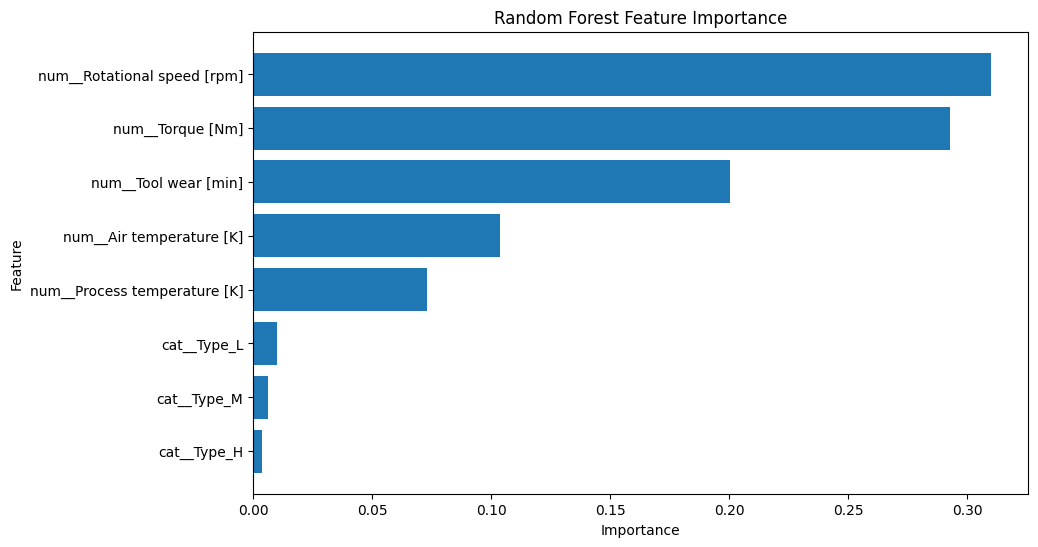

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [65]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                        Feature  Importance
2   num__Rotational speed [rpm]    0.309927
3              num__Torque [Nm]    0.292754
4          num__Tool wear [min]    0.200449
0      num__Air temperature [K]    0.103700
1  num__Process temperature [K]    0.073200
6                   cat__Type_L    0.009904
7                   cat__Type_M    0.006288
5                   cat__Type_H    0.003777


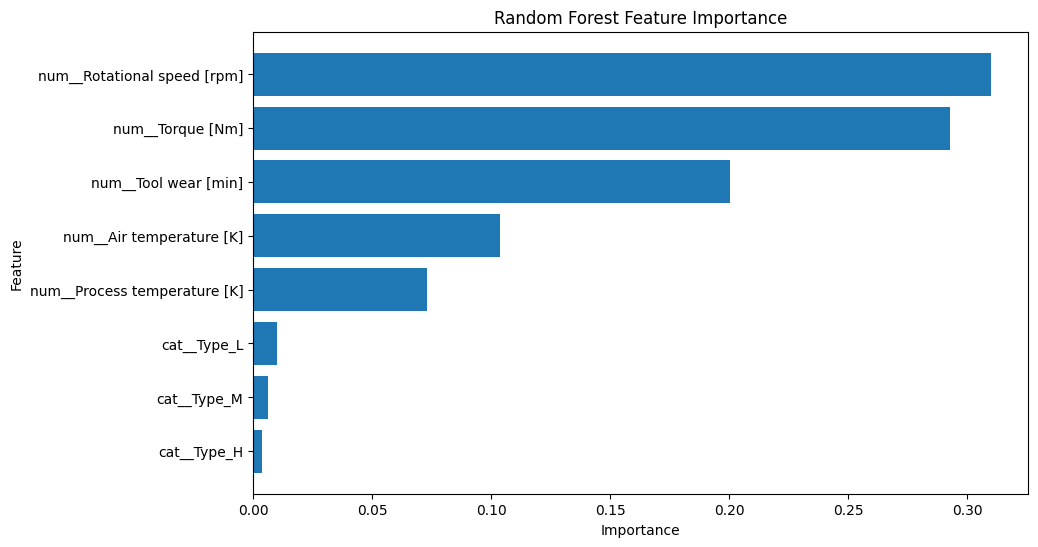

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

| Feature                  | Interpretation          |
| ------------------------ | ----------------------- |
| Torque                   | likely highly important |
| Tool wear                | likely highly important |
| Rotational speed         | potentially important   |
| Process temperature      | moderate/low            |
| Air temperature          | moderate/low            |
| Type_H / Type_L / Type_M | lower contribution      |


**How to interpret it**

Remember:

Feature importance tells us how much a feature contributes to the Random Forest's decision-making. It does NOT mean the feature causes machine failure.

For example, if Torque has the highest importance:

Torque contributes strongly to separating failure and non-failure cases.
This agrees with our earlier analysis where torque had the strongest correlation with the target.
Tool wear may also be important, which agrees with its higher values among failed machines.
Temperature features may have lower importance because there was substantial overlap between failure and non-failure groups.

Also remember that feature importance is model-specific.

### Step 1 — Create the final deployment pipeline
Since your original notebook already has preprocessor, X_train, y_train, etc., run this:

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

final_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", final_model)
])

### Step 2 — Train it

In [70]:
final_pipeline.fit(X_train, y_train)

print("Final pipeline trained successfully.")

Final pipeline trained successfully.


This is essentially combining the two stages you previously did separately:

Raw Data
   ↓
Preprocessor
   ├── StandardScaler
   └── OneHotEncoder
   ↓
Random Forest
   ↓
Prediction

### Step 3 — Evaluate the final pipeline

In [71]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

final_proba = final_pipeline.predict_proba(X_test)[:, 1]

final_threshold = 0.30

final_pred = (final_proba >= final_threshold).astype(int)

print("Final Confusion Matrix:")
print(confusion_matrix(y_test, final_pred))

print("\nFinal Classification Report:")
print(classification_report(y_test, final_pred))

print("\nFinal ROC-AUC:")
print(roc_auc_score(y_test, final_proba))

Final Confusion Matrix:
[[1918   14]
 [  22   46]]

Final Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.77      0.68      0.72        68

    accuracy                           0.98      2000
   macro avg       0.88      0.83      0.85      2000
weighted avg       0.98      0.98      0.98      2000


Final ROC-AUC:
0.963596851784192


Important

We're deliberately using:

final_threshold = 0.30

because we previously found that 0.30 gave the best F1 among the thresholds we tested:

Precision ≈ 0.767
Recall ≈ 0.676
F1 ≈ 0.719

### Step 4 — Save the model

In [72]:
import os

model_path = r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Predictive-Maintenance-ML\models"

os.makedirs(model_path, exist_ok=True)

In [73]:
import joblib

model_artifact = {
    "pipeline": final_pipeline,
    "threshold": 0.30
}

joblib.dump(
    model_artifact,
    os.path.join(
        model_path,
        "predictive_maintenance_model.pkl"
    )
)

print("Model saved successfully.")

Model saved successfully.


### Step 5 — Verify that the saved model works

This is important before we move to Streamlit.

In [74]:
loaded_model = joblib.load(
    r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Predictive-Maintenance-ML\models\predictive_maintenance_model.pkl"
)

loaded_pipeline = loaded_model["pipeline"]
loaded_threshold = loaded_model["threshold"]

print("Model loaded successfully.")
print("Threshold:", loaded_threshold)

Model loaded successfully.
Threshold: 0.3


In [75]:
sample = X_test.iloc[[0]]

probability = loaded_pipeline.predict_proba(sample)[0, 1]

prediction = int(probability >= loaded_threshold)

print("Failure Probability:", probability)
print("Prediction:", prediction)

Failure Probability: 0.12
Prediction: 0


* Prediction = 0 → No Failure
* Prediction = 1 → Failure

* Prediction = 0 → No Failure
* Prediction = 1 → Failure

In [76]:
import joblib
import os

model_path = r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Predictive-Maintenance-ML\models"

os.makedirs(model_path, exist_ok=True)

joblib.dump(
    {
        "pipeline": final_pipeline,
        "threshold": 0.30
    },
    os.path.join(
        model_path,
        "predictive_maintenance_model.pkl"
    )
)

print("MODEL SAVED")
print(os.path.join(model_path, "predictive_maintenance_model.pkl"))

MODEL SAVED
C:\Users\user\Downloads\AI_Engineer\ML_Projects\Predictive-Maintenance-ML\models\predictive_maintenance_model.pkl


In [77]:
import joblib
import pandas as pd

model_path = r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Predictive-Maintenance-ML\models\predictive_maintenance_model.pkl"

artifact = joblib.load(model_path)

pipeline = artifact["pipeline"]
threshold = artifact["threshold"]

test_machine = pd.DataFrame({
    "Type": ["M"],
    "Air temperature [K]": [300.0],
    "Process temperature [K]": [310.0],
    "Rotational speed [rpm]": [1500],
    "Torque [Nm]": [60.0],
    "Tool wear [min]": [200]
})

probability = pipeline.predict_proba(test_machine)[0, 1]

prediction = int(probability >= threshold)

print("Failure Probability:", probability)
print("Failure Probability %:", probability * 100)
print("Prediction:", prediction)

Failure Probability: 0.265
Failure Probability %: 26.5
Prediction: 0
